# VIVID Tutorial

This tutorial demonstrates the VIVID reconstruction workflow using two observed MERFISH mouse olfactory bulb sections, with aligned spatial coordinates and `cell_type` annotations. The same workflow also supports multiple observed sections, reconstructing intermediate sections within each adjacent interval.

Before running, install VIVID and the required dependencies, download the pretrained RIFE weights, and configure a valid Gurobi license as described in the [README](../README.md). The MERFISH mouse olfactory bulb dataset is not included in this repository.

The following cell initializes the environment and imports `vivid`. If the repository is not detected automatically, specify its location using `REPO_ROOT`.

In [1]:
from pathlib import Path
import sys

# Set this only when Jupyter starts outside this checkout and its parent folders.
REPO_ROOT = None  # Example: "/absolute/path/to/VIVID"

bases = [Path.cwd(), *Path.cwd().parents]
candidates = ([Path(REPO_ROOT).expanduser()] if REPO_ROOT is not None else
              [p for base in bases for p in (base, base / "VIVID")])
ROOT = next((p.resolve() for p in candidates
             if (p / "src/vivid/api.py").is_file() and (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Set REPO_ROOT to the VIVID checkout containing pyproject.toml and src/vivid/.")

# Import this checkout directly; an editable installation is optional here.
sys.path.insert(0, str(ROOT / "src"))
import vivid

if Path(vivid.__file__).resolve().parent != ROOT / "src/vivid":
    raise RuntimeError("Another vivid checkout is cached. Restart the kernel and run this cell again.")
print(f"Kernel Python: {sys.executable}\nRepository: {ROOT}\nVIVID source: {vivid.__file__}")


/home/sibh/.conda/envs/sibh/lib/python3.12/site-packages/torch/utils/_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(
2026-10-31 15:50:18.018407: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-31 15:50:18.026791: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-31 15:50:18.029503: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-31 15:50:18.452510: W tensor

Kernel Python: /home/sibh/.conda/envs/sibh/bin/python
Repository: /mnt/disk3/sibh/20_Spatiotemporal/20261001Model/VIVID
VIVID source: /mnt/disk3/sibh/20_Spatiotemporal/20261001Model/VIVID/src/vivid/__init__.py


## 1. Load observed sections

Specify the paths to the observed `.h5ad` files in `input_paths` and their corresponding identifiers in `slice_names`, following the physical section order. This example uses sections 6 and 8; the intervening section 7 is not used as input.

In [2]:
input_paths = [
    ROOT.parent.parent / "data/20260615_3DMB/slice_6_corrected_spatial.h5ad",
    ROOT.parent.parent / "data/20260615_3DMB/slice_8_corrected_spatial.h5ad",
]
slice_names = ["6", "8"]  # User-defined names, independent of the file basenames.

inputs = vivid.read_inputs(input_paths, slice_names=slice_names, celltype_key="cell_type")


Loaded 6: 16,861 observations | /mnt/disk3/sibh/20_Spatiotemporal/data/20260615_3DMB/slice_6_corrected_spatial.h5ad
Loaded 8: 22,840 observations | /mnt/disk3/sibh/20_Spatiotemporal/data/20260615_3DMB/slice_8_corrected_spatial.h5ad


### Optional: Multiple observed sections

VIVID also supports multiple observed sections, reconstructing intermediate sections between each adjacent pair. For example, to use MB1 sections 6, 7 and 8:

```
input_paths = [
    ROOT.parent.parent / "data/20260615_3DMB/slice_6_corrected_spatial.h5ad",
    ROOT.parent.parent / "data/20260615_3DMB/slice_7_corrected_spatial.h5ad",
    ROOT.parent.parent / "data/20260615_3DMB/slice_8_corrected_spatial.h5ad",
]
slice_names = ["6", "7", "8"]
``` 
With target_number=1, VIVID reconstructs one intermediate section between sections 6–7 and another between sections 7–8. All three supplied sections are treated as observed inputs.

### Optional: Expression preprocessing

For the MERFISH mouse olfactory bulb dataset, retain shared features, normalize total counts to 10,000 per cell, and apply log1p transformation. Skip this step if the input data have already been preprocessed.

In [3]:
inputs = vivid.preprocess_inputs(inputs, target_sum=1e4, log1p=True, common_features=True)

### Spatial alignment

All observed sections must share a common spatial coordinate system. The MERFISH mouse olfactory bulb inputs are already aligned, so this step can be skipped.

For unaligned single-omics data, VIVID provides an optional OT-based rigid alignment method. Other alignment methods can also be used, provided the resulting sections share a common coordinate system.

In [4]:
ALREADY_ALIGNED = True
if not ALREADY_ALIGNED:
    inputs = vivid.align_inputs(inputs, same_omics=True)

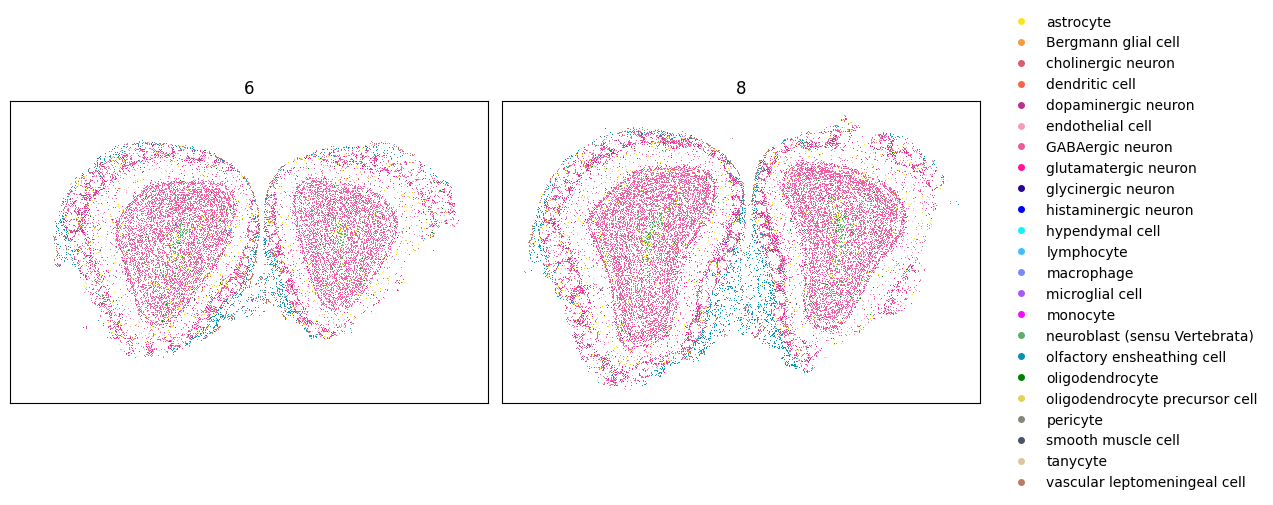

In [5]:
vivid.plot_inputs(inputs, point_size=0.5)

## 2. Configure VIVID

Configure the number of intermediate sections per adjacent pair (`target_number`), spatial resolution (`singlecell` or `bin`), optional z-coordinate generation, image encoding, interpolation model, and optimization solver.

This example uses GNN encoding, RIFE interpolation, and Gurobi optimization. For cross-omics reconstruction, specify the modality of each observed section using `slice_omics`. See the [README](../README.md) for additional model configurations and environment requirements.

Set `save_intermediates=True` to retain intermediate results; otherwise, only the final reconstructed sections are saved. All outputs are organized under a dataset-specific directory.

In [6]:
run = vivid.configure(
    inputs, dataset_name="MB1", target_number=1,
    resolution="singlecell", 
    left_omics="RNA", right_omics="RNA",
    encoding="gnn",  # 'gnn': context-aware encoding; 'pca': PCA-based contextual encoding; 'spherical': spherical encoding
    interpolation="RIFE", # "GIMM-VFI"  "FILM"
    optimization_solver="gurobi",
    model_root=ROOT, backend_python=None,
    save_root=ROOT / "save", save_intermediates=False,

    generation_z=False,
    advanced={"z_section_thickness": 10.0},  # if generation_z = True 
)
print(f"Save directory: {run.output_dir}")
vivid.check_backend(run)

Save directory: /mnt/disk3/sibh/20_Spatiotemporal/20261001Model/VIVID/save/MB1_GNN_RIFE_Oct31_15_50
Observed slices: ['6', '8']
Adjacent pairs: 1 | Targets per pair: 1 | Total targets: 1
Save directory: /mnt/disk3/sibh/20_Spatiotemporal/20261001Model/VIVID/save/MB1_GNN_RIFE_Oct31_15_50
RIFE: inference script and weight files found. Python: /home/sibh/.conda/envs/sibh/bin/python3.12


True

When `generation_z=True`, specify the section thickness in micrometers using `advanced={"z_section_thickness": 10.0}`. Note that z coordinates are generated independently for each adjacent interval and do not automatically form a globally consistent 3D coordinate system.

## 3. Select raster resolution

VIVID automatically selects the raster resolution based on the spatial sampling characteristics of the two observed endpoints. For multiple observed sections, the resolution is determined independently for each adjacent pair.

In [7]:
image_sizes = vivid.select_image_size(run)
image_sizes

[1/1] 6 / 8: select_image_size
Selecting image size from the two observed endpoints...
Selected canvas: 1024 × 1024


{('6', '8'): 1024}

## 4. Encode spatial-omics sections

VIVID encodes each adjacent pair of observed sections into three-channel images representing annotation identity, local tissue context and spatial occupancy. The default method uses context-aware encoding.

Use `pair_index` (starting from 0) to visualize the encoded images for different adjacent pairs.

In [8]:
vivid.encode(run)

[1/1] 6 / 8: encode
Encoding: rasterizing cell types and constructing the shared grid...
Global grid:
  H: 1024
  W: 1024
  x_min: -1781.8312941230322
  x_max: 1931.8589281505099
  y_min: -1972.5225296916742
  y_max: 1741.1676925818679
  raw_x_min: -1781.8312941230322
  raw_x_max: 1931.8589281505099
  raw_y_min: -1288.8201976378389
  raw_y_max: 1057.4653605280328
  pixel_size: 3.626650607689006
  pixel_size_x: 3.626650607689006
  pixel_size_y: 3.626650607689006
  margin_pixels: 0
  inner_H: 1024
  inner_W: 1024
  actual_margin_left_pixels: 0.0
  actual_margin_right_pixels: 0.0
  actual_margin_top_pixels: 188.52169839694258
  actual_margin_bottom_pixels: 188.52169839694253

Number of cell types: 23
Output shape per slice: (1024, 1024, 25)

Spatial resolution diagnostics:
  Raster size              : 1024 × 1024
  Pixel size Δ_H           : 3.62665
  Spatial-unit mode        : cell
  Gaussian sigma           : 1 pixels
  Gaussian FWHM            : 2.35482 pixels
  V_H^cell definition    

/mnt/disk3/sibh/20_Spatiotemporal/20261001Model/VIVID/src/vivid/_core/raster.py:93: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  return sorted(pd.unique(all_types).tolist())


Saved slice_1 to: /tmp/vivid_c3zedpnq/slice_1_density.npz
Saved slice_2 to: /tmp/vivid_c3zedpnq/slice_2_density.npz
Encoding: smoothing global density and computing latent RGB images...


Train context-aware cell AE:   0%|          | 0/1000 [00:00<?, ?it/s]

Create context-aware latent RGB:   0%|          | 0/2 [00:00<?, ?it/s]

Encoding complete. Use vivid.plot_encoding(session) to inspect both endpoints.


SeriesSession(inputs={'6': AnnData object with n_obs × n_vars = 16861 × 1120
    obs: 'donor_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'cluster_id_transfer', 'subclass_transfer', 'cluster_confidence_score', 'subclass_confidence_score', 'high_quality_transfer', 'major_brain_region', 'ccf_region_name', 'brain_section_label', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'gene_name', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title', 'log1p'
    obsm: 'X_CCF', 'X_spatial_coords', 'X_umap', 'spa

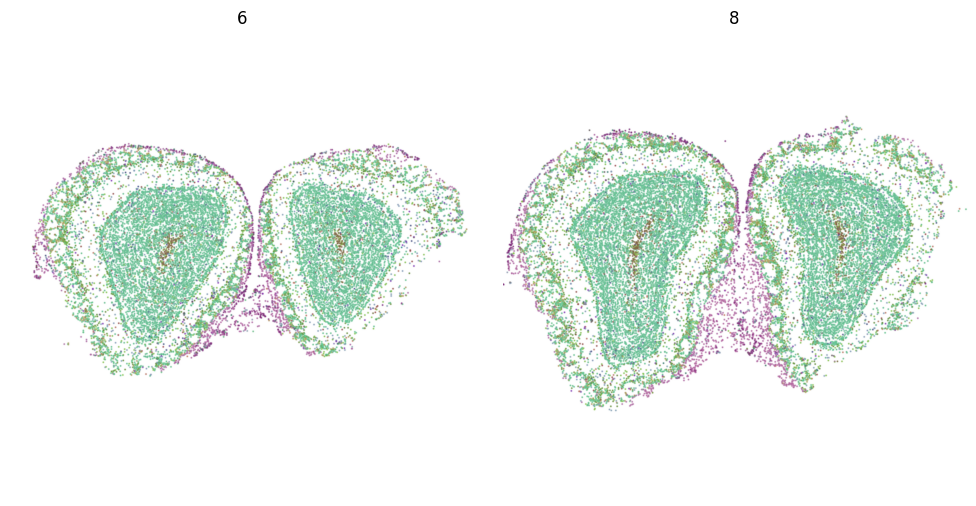

In [9]:
vivid.plot_encoding(run, pair_index=0)

## 5. Infer correspondence

A frozen pretrained interpolation backbone processes the encoded endpoint images to generate an auxiliary intermediate image and target-to-endpoint correspondence fields at each target depth.

Use `pair_index` (starting from 0) to visualize the interpolation results for different adjacent pairs.

In [10]:
vivid.interpolate(run)

[1/1] 6 / 8: interpolate
RIFE: inference script and weight files found. Python: /home/sibh/.conda/envs/sibh/bin/python3.12
Interpolating encoded endpoints with RIFE...
Interpolation complete; selected frames: [1]


SeriesSession(inputs={'6': AnnData object with n_obs × n_vars = 16861 × 1120
    obs: 'donor_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'cluster_id_transfer', 'subclass_transfer', 'cluster_confidence_score', 'subclass_confidence_score', 'high_quality_transfer', 'major_brain_region', 'ccf_region_name', 'brain_section_label', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'gene_name', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title', 'log1p'
    obsm: 'X_CCF', 'X_spatial_coords', 'X_umap', 'spa

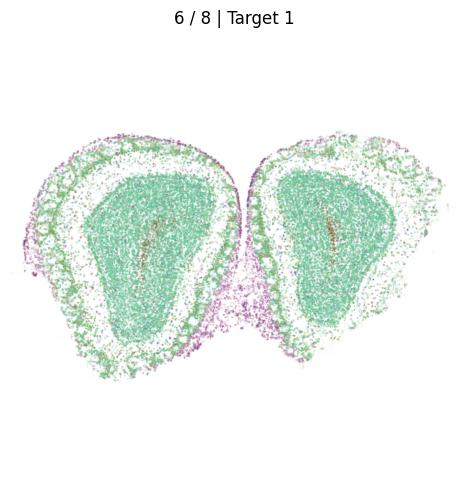

In [11]:
vivid.plot_interpolation(run, pair_index=0)

## 6. Reconstruct spatial-omics sections

Using the inferred correspondence fields and measured endpoint information, VIVID hierarchically reconstructs spatial density, coordinates, annotations and molecular profiles at the requested depths.

The reconstructed sections are returned as AnnData objects and can be visualized alongside the observed inputs.

In [12]:
predictions = vivid.reconstruct(run)

[1/1] 6 / 8: reconstruct
Detecting sites and conserving the interpolated total cell count...
Mapping flow and estimating cell type proportions...


RIFE cell-type proportions:   0%|          | 0/1 [00:00<?, ?it/s]

Preparing optimization inputs:   0%|          | 0/1 [00:00<?, ?it/s]

Integer allocation optimization:   0%|          | 0/1 [00:00<?, ?it/s]

Optimizing integer cell type allocations with Gurobi...


Preparing neighborhood lookup:   0%|          | 0/9223 [00:00<?, ?it/s]

... (4 outputs left out)

Assigning optional continuous z coordinates...
Building target AnnData objects...
Predicting expression using flow and microenvironment fallback...


,model,pair_name,image_name,n_cells,left_flow_local,right_flow_local,left_microenv,right_microenv,left_available,right_available,both_sides,only_left,only_right,fusion_source,key
0,RIFE,slice_1_to_slice_2,img1.png,19706,15977,16209,671,669,16648,16878,13820,2828,3058,time,RIFE__slice_1_to_slice_2__img1.png


,model,n_frames,n_cells,left_flow_local,right_flow_local,left_microenv,right_microenv,left_available,right_available
0,RIFE,1,19706,15977,16209,671,669,16648,16878


Reconstruction complete: 1 target AnnData objects.


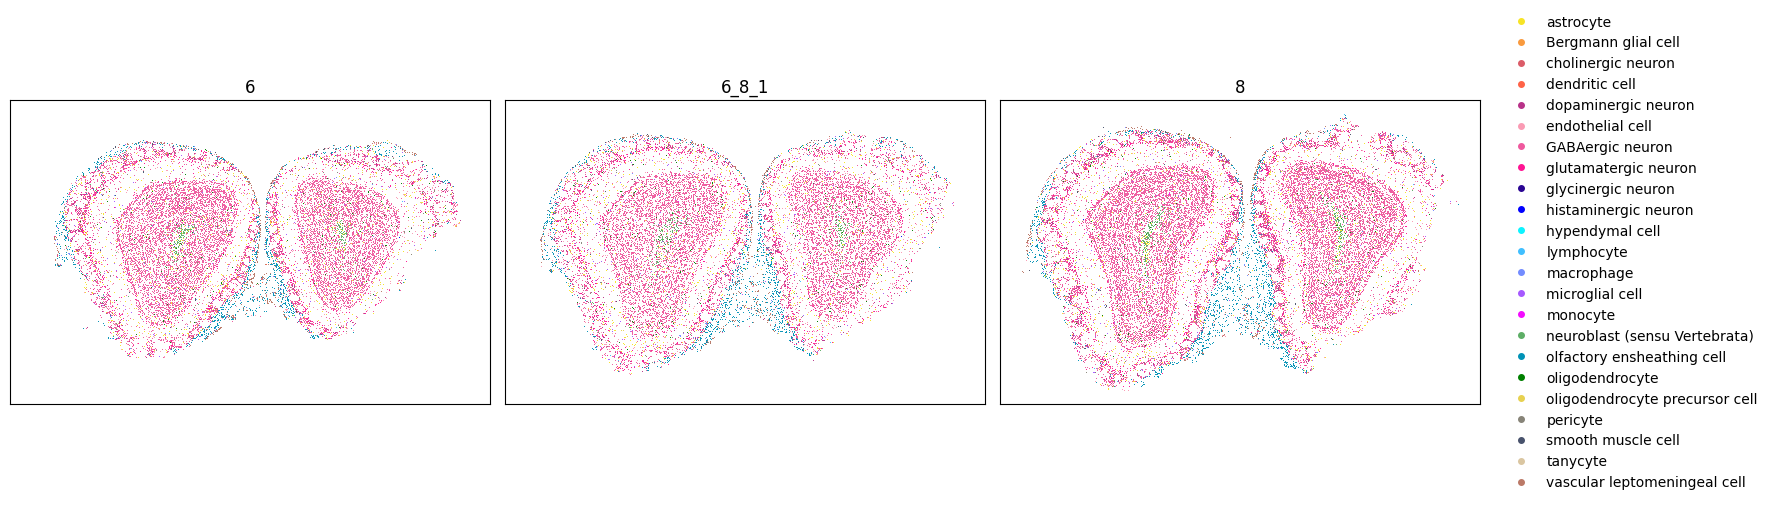

In [13]:
vivid.plot_predictions(run, point_size=0.5)

6_8_1


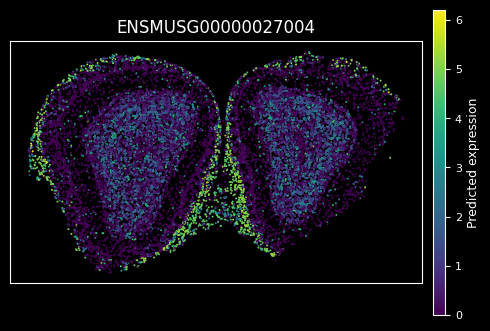

In [16]:
#plot predicted features 
target_name, target = next(iter(predictions.items()))
print(target_name)

vivid.plot_feature(target, 'ENSMUSG00000027004', point_size=2.0)


## 7. Save reconstructed sections

Save the reconstructed sections as `.h5ad` files in the dataset-specific output directory. Each file is named using the observed endpoint identifiers and target index (for example, `6_8_1.h5ad`).

By default, only the final reconstructed sections are retained. Set `save_intermediates=True` during configuration to preserve intermediate results.

In [17]:
paths = vivid.save_results(run)
paths


[1/1] 6 / 8: save_results
Saved 1 h5ad files to /mnt/disk3/sibh/20_Spatiotemporal/20261001Model/VIVID/save/MB1_GNN_RIFE_Oct31_15_50


[PosixPath('/mnt/disk3/sibh/20_Spatiotemporal/20261001Model/VIVID/save/MB1_GNN_RIFE_Oct31_15_50/6_8_1.h5ad')]